# Lightning Talk #2 — Dota 2 Winning-Team Prediction
**General Assembly × Tamkeen | Capstone Part 2 | EDA and Project Plan**  
**Dataset:** [Dota 2 Matches (Kaggle)](https://www.kaggle.com/datasets/devinanzelmo/dota-2-matches)  
**Prediction moment:** After all ten heroes have been selected, **before gameplay**.

This notebook follows the instructor's November 22 Lightning Talk #2 checklist. It presents **EDA and a proposed modeling plan**, not completed model results. All graphs and numerical summaries are calculated from the CSVs when the notebook runs.

**Run:** Put `match.csv` and `players.csv` (or their `(1)` variants) beside this notebook, or in `/mnt/data`, then **Restart & Run All**. All imports appear in the first code cell.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

SEARCH_DIRS = [Path.cwd(), Path("/mnt/data"), Path.cwd() / "data"]
def find_csv(stem):
    for folder in SEARCH_DIRS:
        for name in (f"{stem}.csv", f"{stem}(1).csv"):
            p = folder / name
            if p.is_file():
                return p
    raise FileNotFoundError(f"Cannot locate {stem}.csv. Put it next to the notebook.")

match_path, player_path = find_csv("match"), find_csv("players")
matches = pd.read_csv(match_path)
players = pd.read_csv(player_path)
print(f"Loaded {match_path.name}: {matches.shape[0]:,} rows × {matches.shape[1]} columns")
print(f"Loaded {player_path.name}: {players.shape[0]:,} rows × {players.shape[1]} columns")

Loaded match.csv: 50,000 rows × 13 columns
Loaded players.csv: 500,000 rows × 73 columns


## 1. Updated Problem Statement, Audience and SMART Objectives

**Problem statement.** In this historical sample of 50,000 Dota 2 matches, Radiant won approximately 51.9% and Dire won 48.1%. Esports coaches and analysts must evaluate matchups after hero selection, when the winning side is still unknown. We will investigate whether the ten selected heroes can support more useful pre-game predictions than simply choosing the historically more common winner.

**Audience:** Esports coaches, analysts, competitive players and tournament commentators.  
**Goal:** Predict `radiant_win` from hero selections available **before** the match begins.

**SMART objectives — by the end of the capstone project:**
1. Describe the winner distribution and examine the available data, including categorical frequencies, missingness, correlations and outliers.
2. Construct match-level features from the five Radiant and five Dire hero selections, checking that every included feature is available before gameplay.
3. Compare candidate classifiers against a majority-class baseline on held-out matches using **accuracy, F1, balanced accuracy and a confusion matrix** (and log loss if predicted probabilities are available).

*Time-bound refers to the capstone completion milestone, not to the years in the historical dataset. The numerical results below are descriptive; no classifier has been trained.*

## 2. Target: Meaning, Type and Balance
- **Target column:** `radiant_win` in `match.csv`.
- **Meaning:** `True` = Radiant won; `False` = Dire won.
- **Type:** **Categorical (binary)**, not continuous.
- **Baseline:** Always predict the most common winner in the **training data**; the full-sample majority rate below is only an EDA reference.

,Outcome,Count,Percent
0,Radiant win,25943,51.89
1,Dire win,24057,48.11


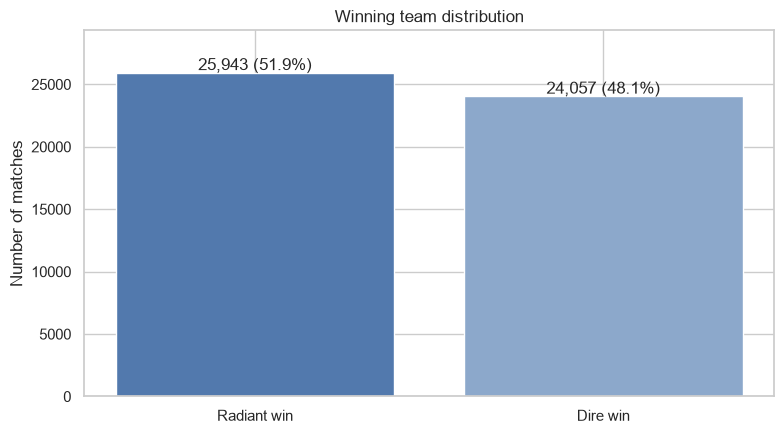

Full-sample majority-class rate: 51.89% (not test-set model performance)


In [2]:
target_counts = matches["radiant_win"].value_counts().reindex([True, False], fill_value=0)
target_table = pd.DataFrame({"Outcome": ["Radiant win", "Dire win"], "Count": target_counts.values,
                             "Percent": (100 * target_counts.values / len(matches)).round(2)})
display(target_table)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(target_table["Outcome"], target_table["Count"], color=["#5279ad", "#8ca8cb"])
for i, r in target_table.iterrows():
    ax.text(i, r["Count"] + 200, f'{r["Count"]:,} ({r["Percent"]:.1f}%)', ha="center")
ax.set(title="Winning team distribution", ylabel="Number of matches", ylim=(0, target_table["Count"].max()*1.13))
plt.tight_layout(); plt.show()
print(f"Full-sample majority-class rate: {target_counts.max()/len(matches):.2%} (not test-set model performance)")

## 3. Feature Inventory: Numerical vs Categorical
The raw CSVs contain many **post-game** variables. Feature *type* and feature *eligibility* are different questions: a numerical column is not automatically appropriate for a pre-game model.

**Classification rule:** IDs, binary indicators, `hero_id`, `player_slot`, `game_mode`, `cluster`, and `leaver_status` are treated as categorical for EDA even if stored as integers. The `unit_order_*` columns are numerical counts, but represent gameplay. `match_id` is an identifier, not a predictor. `start_time` is a timestamp (a separate type). The remaining numeric columns are numerical. This is a semantic grouping, not simply `pandas` dtype.

In [3]:
CATEGORICAL_MATCH = {"radiant_win", "game_mode", "cluster"}
CATEGORICAL_PLAYER = {"account_id", "hero_id", "player_slot", "leaver_status"}
ID_COLUMNS = {"match_id"}
TIME_COLUMNS = {"start_time"}

def inventory(df, table_name, categorical):
    rows = []
    for col in df.columns:
        kind = ("Identifier" if col in ID_COLUMNS else "Datetime" if col in TIME_COLUMNS else
                "Categorical" if col in categorical or df[col].dtype == "object" else "Numerical")
        rows.append({"Table": table_name, "Feature": col, "Pandas dtype": str(df[col].dtype),
                     "EDA type": kind, "Unique non-null": df[col].nunique(dropna=True)})
    return pd.DataFrame(rows)
feature_inventory = pd.concat([inventory(matches, "match", CATEGORICAL_MATCH),
                               inventory(players, "players", CATEGORICAL_PLAYER)], ignore_index=True)
display(feature_inventory.groupby(["Table", "EDA type"]).size().rename("Columns").reset_index())
display(feature_inventory)
print("Counts above include the target and ID/timestamp columns in their own categories; they are not all modeling features.")

,Table,EDA type,Columns
0,match,Categorical,3
1,match,Datetime,1
2,match,Identifier,1
3,match,Numerical,8
4,players,Categorical,4
5,players,Identifier,1
6,players,Numerical,68


,Table,Feature,Pandas dtype,EDA type,Unique non-null
0,match,match_id,int64,Identifier,50000
1,match,start_time,int64,Datetime,46836
2,match,duration,int64,Numerical,3573
3,match,tower_status_radiant,int64,Numerical,127
4,match,tower_status_dire,int64,Numerical,128
5,match,barracks_status_dire,int64,Numerical,48
6,match,barracks_status_radiant,int64,Numerical,51
7,match,first_blood_time,int64,Numerical,550
8,match,game_mode,int64,Categorical,2
9,match,radiant_win,bool,Categorical,2


Counts above include the target and ID/timestamp columns in their own categories; they are not all modeling features.


## 4. Categorical Features: Unique Values and Percentages
For **each categorical column**, the next cell reports the number of unique values and a complete frequency/percentage table, including missing values where present. High-cardinality columns such as `account_id` can contain many unique IDs; their full tables are saved as CSV rather than filling hundreds of notebook pages. The notebook displays a readable preview of the top 15 values for each column.

**Important:** `account_id` identifies a player, not a generalizable hero feature; `leaver_status` is observed after/during gameplay and is excluded from prediction.

In [4]:
categorical_tables = {}
for table_name, df, columns in [("match", matches, sorted(CATEGORICAL_MATCH)),
                                ("players", players, sorted(CATEGORICAL_PLAYER))]:
    for col in columns:
        s = df[col].astype("object").where(df[col].notna(), "<MISSING>")
        vc = s.value_counts(dropna=False)
        freq = pd.DataFrame({"Value": vc.index.astype(str), "Count": vc.values,
                             "Percent": (100*vc.values/len(df)).round(4)})
        categorical_tables[(table_name, col)] = freq
        print(f"\n{table_name}.{col}: {df[col].nunique(dropna=True):,} unique non-null values; {len(freq):,} frequency categories including missing")
        display(freq.head(15))
# To inspect every category without truncation: categorical_tables[("match", "game_mode")], etc.
# Save the full frequency tables in one tidy CSV for review.
all_cat = pd.concat([freq.assign(Table=t, Feature=c) for (t,c),freq in categorical_tables.items()], ignore_index=True)
all_cat.to_csv("Dota2_Categorical_Value_Percentages.csv", index=False)
print(f"Saved full categorical tables: Dota2_Categorical_Value_Percentages.csv ({len(all_cat):,} rows)")


match.cluster: 32 unique non-null values; 32 frequency categories including missing


,Value,Count,Percent
0,132,8204,16.408
1,133,6801,13.602
2,121,4168,8.336
3,122,3645,7.290
4,138,3442,6.884
5,123,3091,6.182
6,171,2514,5.028
7,111,1913,3.826
8,112,1861,3.722
9,204,1828,3.656



match.game_mode: 2 unique non-null values; 2 frequency categories including missing


,Value,Count,Percent
0,22,48670,97.34
1,2,1330,2.66



match.radiant_win: 2 unique non-null values; 2 frequency categories including missing


,Value,Count,Percent
0,True,25943,51.886
1,False,24057,48.114


... (5 outputs left out)

,Value,Count,Percent
0,0,488178,97.6356
1,1,7019,1.4038
2,2,2598,0.5196
3,3,1670,0.3340
4,4,535,0.1070



players.player_slot: 10 unique non-null values; 10 frequency categories including missing


,Value,Count,Percent
0,0,50000,10.0
1,1,50000,10.0
2,2,50000,10.0
3,3,50000,10.0
4,4,50000,10.0
5,128,50000,10.0
6,129,50000,10.0
7,130,50000,10.0
8,131,50000,10.0
9,132,50000,10.0


Saved full categorical tables: Dota2_Categorical_Value_Percentages.csv (158,523 rows)


## 5. Missing Values: Every Feature in Both Tables
Report missing counts and percentages for **all** columns, including columns with zero missing values. Many `unit_order_*` fields may have extensive missingness; these are gameplay variables and will not be used as pre-game predictors.

,Table,Feature,Missing,Missing %
0,match,match_id,0,0.00
1,match,start_time,0,0.00
2,match,duration,0,0.00
3,match,tower_status_radiant,0,0.00
4,match,tower_status_dire,0,0.00
5,match,barracks_status_dire,0,0.00
6,match,barracks_status_radiant,0,0.00
7,match,first_blood_time,0,0.00
8,match,game_mode,0,0.00
9,match,radiant_win,0,0.00


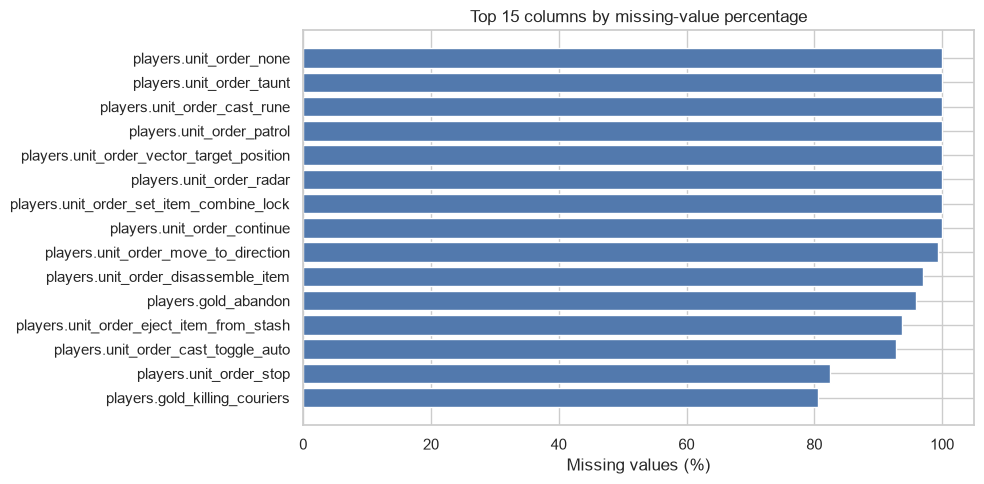

In [5]:
missing_tables = []
for table_name, df in [("match", matches), ("players", players)]:
    missing_tables.append(pd.DataFrame({"Table": table_name, "Feature": df.columns,
        "Missing": df.isna().sum().values,
        "Missing %": (100 * df.isna().mean()).round(2).values}))
missing_report = pd.concat(missing_tables, ignore_index=True)
display(missing_report)
missing_report.to_csv("Dota2_Missing_Values_All_Features.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 5))
top_missing = missing_report.query("Missing > 0").nlargest(15, "Missing %")
if len(top_missing):
    labels = top_missing["Table"] + "." + top_missing["Feature"]
    ax.barh(labels.iloc[::-1], top_missing["Missing %"].iloc[::-1], color="#5279ad")
    ax.set(xlabel="Missing values (%)", title="Top 15 columns by missing-value percentage")
else:
    ax.text(.5,.5,"No missing values",ha="center",va="center",transform=ax.transAxes)
plt.tight_layout(); plt.show()

## 6. Match–Player Join and Hero Pick Analysis
A match has two sides of five players. `player_slot < 128` identifies Radiant; `player_slot >= 128` identifies Dire. We check join integrity before computing hero frequencies and observed hero win rates. **A hero's observed win rate is not causal evidence and cannot be used as a target-derived feature computed on the entire dataset during modeling** (that would leak outcomes).

In [6]:
player_counts = players.groupby("match_id").size()
print("Player rows per match:")
display(player_counts.value_counts().sort_index().rename_axis("Players").reset_index(name="Matches"))
print("Duplicate match IDs in match table:", matches["match_id"].duplicated().sum())
hero = players[["match_id", "hero_id", "player_slot"]].merge(
    matches[["match_id", "radiant_win"]], on="match_id", how="inner", validate="many_to_one")
hero["side"] = np.where(hero["player_slot"] < 128, "Radiant", "Dire")
hero["hero_won"] = np.where(hero["side"] == "Radiant", hero["radiant_win"], ~hero["radiant_win"].astype(bool))
print(f"Joined {len(hero):,} player records across {hero.match_id.nunique():,} matches")
print("Matches with 5 Radiant + 5 Dire players:",
      int((hero.groupby(["match_id", "side"]).size().unstack(fill_value=0).eq(5).all(axis=1)).sum()))
hero_stats = hero.groupby("hero_id").agg(picks=("hero_won", "size"), wins=("hero_won", "sum"))
hero_stats["win_rate"] = 100 * hero_stats["wins"] / hero_stats["picks"]
hero_stats = hero_stats.sort_values("picks", ascending=False)
display(hero_stats.head(15).round(2))

Player rows per match:


,Players,Matches
0,10,50000


Duplicate match IDs in match table: 0
Joined 500,000 player records across 50,000 matches
Matches with 5 Radiant + 5 Dire players: 50000


,picks,wins,win_rate
hero_id,,,
21,20881,10026,48.01
11,17007,8785,51.66
74,11676,5733,49.10
7,11323,5700,50.34
28,11181,6254,55.93
39,10590,4744,44.80
8,10394,5362,51.59
100,10306,5269,51.13
73,9823,5095,51.87


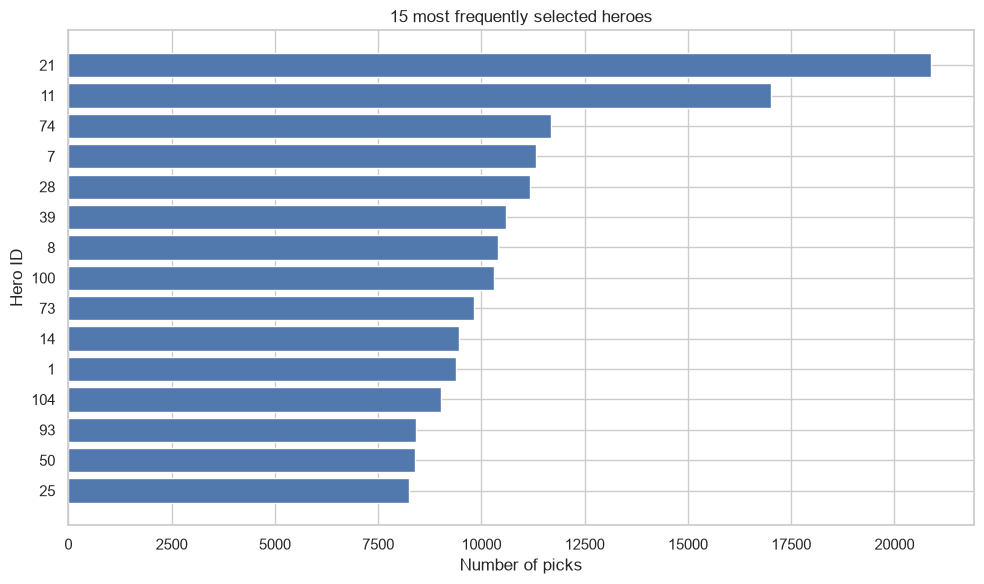

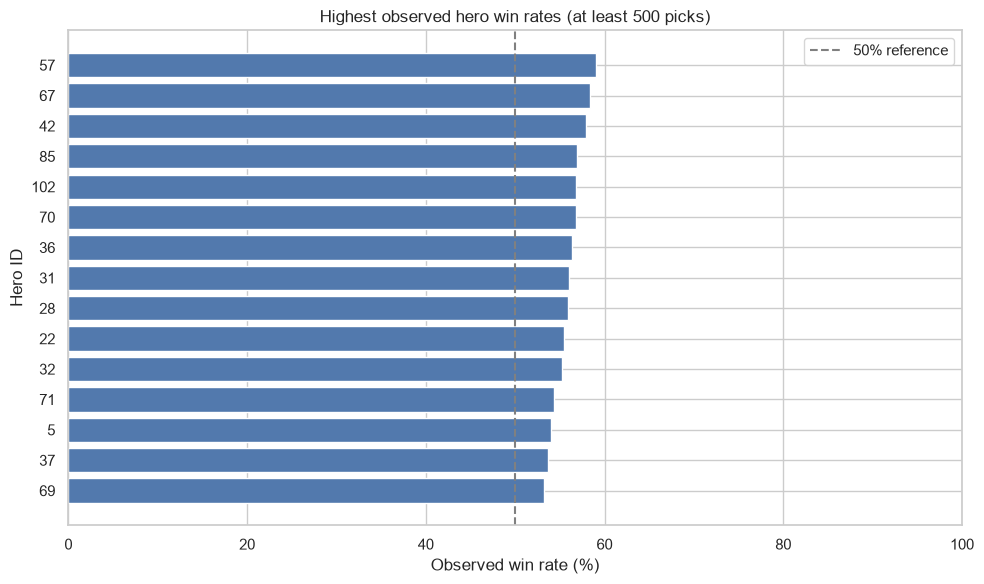

Heroes with at least 500 picks: 110


In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
top = hero_stats.head(15).sort_values("picks")
ax.barh(top.index.astype(str), top["picks"], color="#5279ad")
ax.set(title="15 most frequently selected heroes", xlabel="Number of picks", ylabel="Hero ID")
plt.tight_layout(); plt.show()
MIN_PICKS = 500
eligible = hero_stats[hero_stats["picks"] >= MIN_PICKS].nlargest(15, "win_rate").sort_values("win_rate")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(eligible.index.astype(str), eligible["win_rate"], color="#5279ad")
ax.axvline(50, ls="--", color="gray", label="50% reference")
ax.set(title=f"Highest observed hero win rates (at least {MIN_PICKS} picks)",
       xlabel="Observed win rate (%)", ylabel="Hero ID", xlim=(0, 100))
ax.legend(); plt.tight_layout(); plt.show()
print(f"Heroes with at least {MIN_PICKS} picks: {(hero_stats.picks >= MIN_PICKS).sum()}")

## 7. Correlations: Target and Feature-to-Feature
**Two distinct views are required:**
1. **Exploratory numerical correlations** across raw match columns, which include variables recorded during/after a match. These can be strongly correlated with `radiant_win` but are **not permitted predictors**.
2. **Pre-game associations**, including `game_mode`, `cluster` and hero selection. These are categorical IDs, so ordinary Pearson correlations on their numeric codes are misleading. We show **group-wise Radiant win rates** and **hero–winner associations** instead. This is descriptive EDA only.

A correlation coefficient is not proof of causation. The target is converted to 0/1 **only for calculating correlations**.

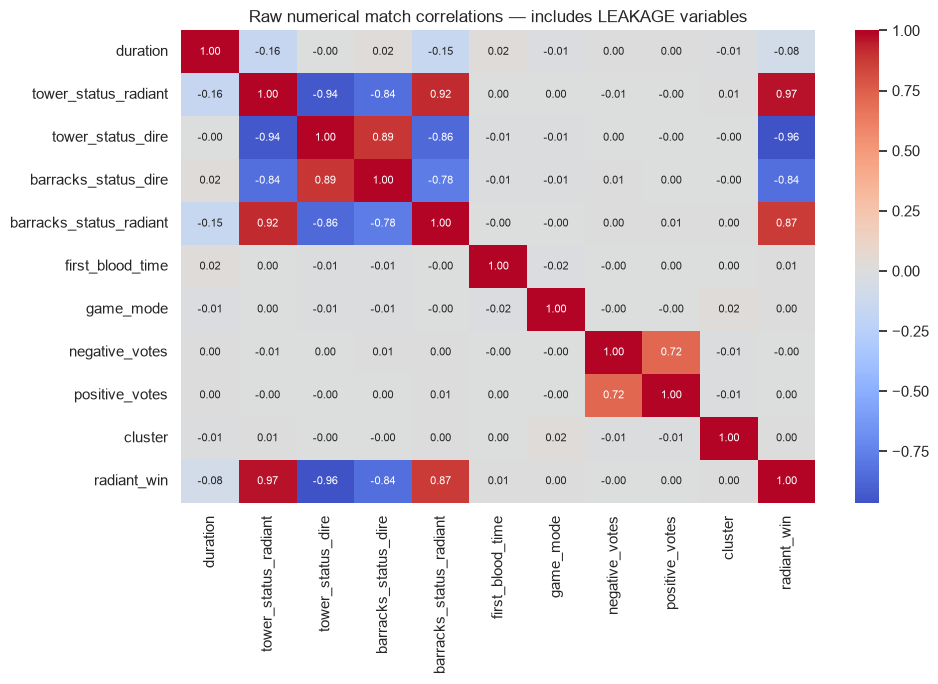

Strongest raw numerical correlations with the target (NOT eligible predictors):


,Pearson r
tower_status_radiant,0.969061
tower_status_dire,-0.964169
barracks_status_radiant,0.873323
barracks_status_dire,-0.837214
duration,-0.079037
first_blood_time,0.005061
cluster,0.004456
negative_votes,-0.004017
game_mode,0.003504
positive_votes,0.000495


Strongest pairwise numerical correlations:


Pearson r
tower_status_radiant    radiant_win               0.969061
tower_status_dire       radiant_win              -0.964169
tower_status_radiant    tower_status_dire        -0.940027
                        barracks_status_radiant   0.919608
tower_status_dire       barracks_status_dire      0.891254
barracks_status_radiant radiant_win               0.873323
tower_status_dire       barracks_status_radiant  -0.862742
barracks_status_dire    radiant_win              -0.837214
tower_status_radiant    barracks_status_dire     -0.835995
barracks_status_dire    barracks_status_radiant  -0.777820
negative_votes          positive_votes            0.720342
duration                tower_status_radiant     -0.164361

In [8]:
numeric_match = matches.select_dtypes(include="number").drop(columns=["match_id", "start_time"], errors="ignore").copy()
numeric_match["radiant_win"] = matches["radiant_win"].astype(int)
corr = numeric_match.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size":8})
ax.set_title("Raw numerical match correlations — includes LEAKAGE variables")
plt.tight_layout(); plt.show()
target_corr = corr["radiant_win"].drop("radiant_win").sort_values(key=lambda x:x.abs(), ascending=False)
print("Strongest raw numerical correlations with the target (NOT eligible predictors):")
display(target_corr.to_frame("Pearson r"))
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("Pearson r")
print("Strongest pairwise numerical correlations:")
display(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(12).to_frame())
print("WARNING: tower/barracks statuses, duration, first blood and votes are not pre-game features.")


game_mode: group-wise target association (top 15 groups by frequency)


,matches,radiant_win_rate
game_mode,,
22,48670,51.91
2,1330,50.83


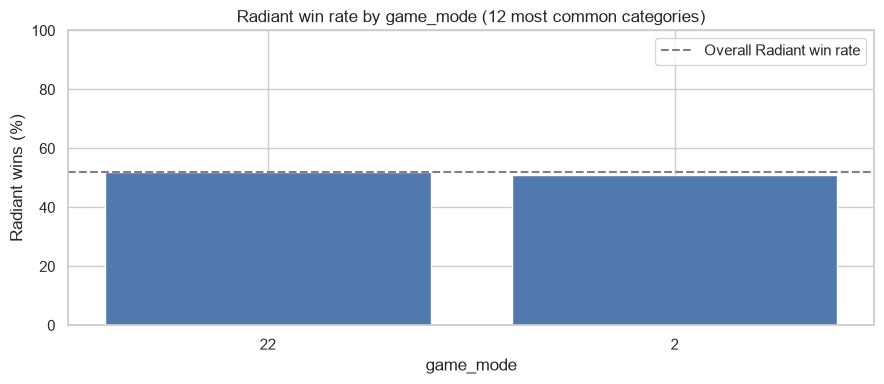


cluster: group-wise target association (top 15 groups by frequency)


,matches,radiant_win_rate
cluster,,
132,8204,50.95
133,6801,52.02
121,4168,51.99
122,3645,52.84
138,3442,51.51
123,3091,51.99
171,2514,51.91
111,1913,51.44
112,1861,50.13


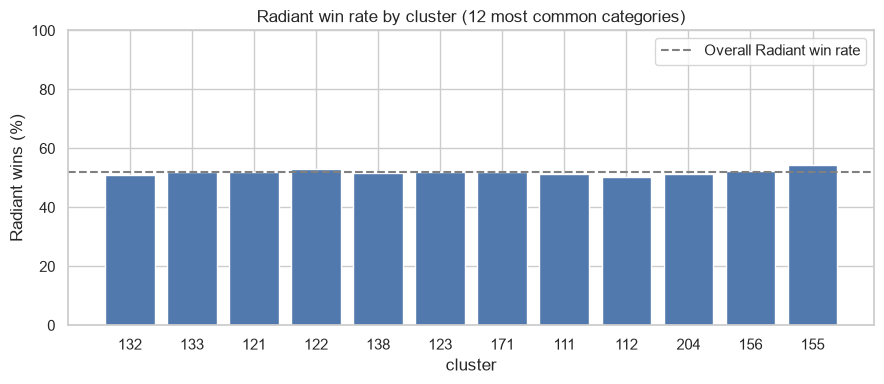

Hero selection associations are summarized in Section 6; group rates must not be copied into model features before splitting the data.


In [9]:
for col in ["game_mode", "cluster"]:
    rates = (matches.groupby(col, dropna=False)["radiant_win"]
             .agg(matches="size", radiant_win_rate="mean").sort_values("matches", ascending=False))
    rates["radiant_win_rate"] *= 100
    print(f"\n{col}: group-wise target association (top 15 groups by frequency)")
    display(rates.head(15).round(2))
    fig, ax = plt.subplots(figsize=(9, 4))
    selected = rates.head(12)
    ax.bar(selected.index.astype(str), selected["radiant_win_rate"], color="#5279ad")
    ax.axhline(100*matches["radiant_win"].mean(), ls="--", color="gray", label="Overall Radiant win rate")
    ax.set(title=f"Radiant win rate by {col} (12 most common categories)",
           ylabel="Radiant wins (%)", xlabel=col, ylim=(0, 100))
    ax.legend(); plt.tight_layout(); plt.show()
print("Hero selection associations are summarized in Section 6; group rates must not be copied into model features before splitting the data.")

## 8. Outliers: Numerical Distributions and IQR
Boxplots and the 1.5×IQR rule identify unusual observations. These are descriptive **post-game** variables; do not remove matches automatically just because a game lasted unusually long. For hero IDs and other categorical codes, numerical outlier detection is not meaningful.

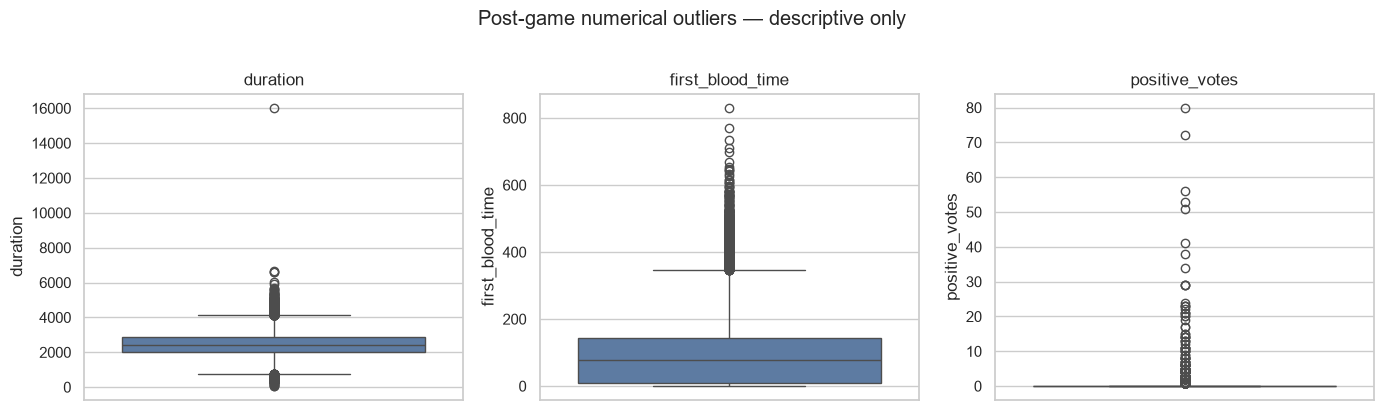

,Feature,Q1,Q3,Lower fence,Upper fence,IQR outliers,Outlier %
0,duration,2029.0,2872.0,764.5,4136.5,647,1.29
1,first_blood_time,9.0,144.0,-193.5,346.5,915,1.83
2,positive_votes,0.0,0.0,0.0,0.0,548,1.10


In [10]:
outlier_cols = [c for c in ["duration", "first_blood_time", "positive_votes"] if c in matches]
rows=[]
fig, axes = plt.subplots(1, len(outlier_cols), figsize=(14, 4))
axes = np.atleast_1d(axes)
for ax,col in zip(axes,outlier_cols):
    x=pd.to_numeric(matches[col],errors="coerce").dropna()
    q1,q3=x.quantile([.25,.75]);iqr=q3-q1;lo=q1-1.5*iqr;hi=q3+1.5*iqr
    rows.append({"Feature":col,"Q1":q1,"Q3":q3,"Lower fence":lo,"Upper fence":hi,
                 "IQR outliers":int(((x<lo)|(x>hi)).sum()),"Outlier %":round(100*((x<lo)|(x>hi)).mean(),2)})
    sns.boxplot(y=x,ax=ax,color="#5279ad");ax.set_title(col)
plt.suptitle("Post-game numerical outliers — descriptive only", y=1.02)
plt.tight_layout();plt.show()
display(pd.DataFrame(rows).round(2))

## 9. Proposed Feature Engineering (Not Yet Trained)
The final prediction table will have **one row per match**, with the target `radiant_win` and features available immediately after hero selection.

| Engineered feature | Construction | Why it may help | Leakage precaution |
|---|---|---|---|
| Ten side-specific hero slots | Five Radiant and five Dire `hero_id` values | Represents both lineups | Only pre-game picks |
| Side-specific hero indicators | One-hot flag for each hero on Radiant / Dire | Learns which heroes are present on each side | Fit encoding on training data |
| Hero-count difference vector | Radiant hero indicator minus Dire indicator | Captures lineup contrast compactly | No outcome statistics |
| Hero pair interactions | Pairs of heroes on the same team (optional) | May capture team synergy | High dimensional; regularize |
| Game mode / cluster | Encode if confirmed known pre-game | May capture different game contexts | Verify availability and avoid arbitrary numeric codes |

**Do not engineer** match-end statistics, player kills, final items, final levels, or full-data hero win-rate features. Historical win-rate encodings would require strictly out-of-fold / training-only computation.

The following code creates an **illustrative match-level feature table**, but does not train a model.

In [11]:
picks = hero[["match_id", "hero_id", "side", "player_slot"]].copy()
picks = picks.sort_values(["match_id", "side", "player_slot"])
picks["slot_number"] = picks.groupby(["match_id", "side"]).cumcount() + 1
picks["feature"] = picks["side"].str.lower() + "_hero_" + picks["slot_number"].astype(str)
wide = picks.pivot(index="match_id", columns="feature", values="hero_id")
expected = [f"radiant_hero_{i}" for i in range(1,6)] + [f"dire_hero_{i}" for i in range(1,6)]
wide = wide.reindex(columns=expected)
match_level = matches[["match_id", "radiant_win"]].merge(wide.reset_index(), on="match_id", how="left", validate="one_to_one")
print("Match-level table shape:",match_level.shape)
print("Matches with any missing hero slot:",int(match_level[expected].isna().any(axis=1).sum()))
display(match_level.head(5))
print("IMPORTANT: hero_id columns are categorical IDs, not ordered numeric measurements.")

Match-level table shape: (50000, 12)
Matches with any missing hero slot: 0


,match_id,radiant_win,radiant_hero_1,radiant_hero_2,radiant_hero_3,radiant_hero_4,radiant_hero_5,dire_hero_1,dire_hero_2,dire_hero_3,dire_hero_4,dire_hero_5
0,0,True,86,51,83,11,67,106,102,46,7,73
1,1,False,7,82,71,39,21,73,22,5,67,106
2,2,False,51,109,9,41,27,38,7,10,12,85
3,3,False,50,44,32,26,39,78,19,31,40,47
4,4,True,8,39,55,87,69,101,100,22,67,21


IMPORTANT: hero_id columns are categorical IDs, not ordered numeric measurements.


## 10. Evaluation Plan: Which Metrics Matter?
**Primary metric: F1 for both sides (macro-F1).** Coaches and analysts need predictions that work for both Radiant and Dire; macro-F1 gives equal weight to each class. **Secondary metrics:** accuracy (easy to compare with the majority baseline), balanced accuracy, per-class precision and recall, and a confusion matrix. If a model outputs reliable probabilities, examine log loss and probability calibration.

**Validation plan:** Split by `match_id` into disjoint training and test matches; if the historical timestamps are trustworthy, prefer a **chronological** split to better reflect prediction on later matches. Compute the majority-class baseline from the **training set only** and evaluate it on the test set. Fit encoders, imputers and feature selection using training data only. Tune models using cross-validation inside training data. Do not claim any trained-model score at this stage.

**Business interpretation:** False confidence about a predicted winner may mislead match previews and draft discussions. Accuracy alone can hide errors on the less common side; macro-F1 and a confusion matrix reveal those mistakes.

In [12]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
# Illustrative majority baseline only: no trained model.
train_ids, test_ids = train_test_split(matches["match_id"], test_size=0.20, random_state=42,
                                      stratify=matches["radiant_win"])
train_y = matches.set_index("match_id").loc[train_ids,"radiant_win"].astype(bool)
test_y = matches.set_index("match_id").loc[test_ids,"radiant_win"].astype(bool)
majority_label = bool(train_y.value_counts().idxmax())
baseline_pred = np.repeat(majority_label, len(test_y))
print("Illustrative stratified holdout; baseline predicts:", "Radiant" if majority_label else "Dire")
print("Baseline accuracy:",round(accuracy_score(test_y,baseline_pred),4))
print("Baseline macro-F1:",round(f1_score(test_y,baseline_pred,average="macro",zero_division=0),4))
print("Baseline balanced accuracy:",round(balanced_accuracy_score(test_y,baseline_pred),4))
print("Confusion matrix [Dire, Radiant]:\n",confusion_matrix(test_y,baseline_pred,labels=[False,True]))
print("This is a dummy baseline, NOT a hero-based machine-learning result.")

Illustrative stratified holdout; baseline predicts: Radiant
Baseline accuracy: 0.5189
Baseline macro-F1: 0.3416
Baseline balanced accuracy: 0.5
Confusion matrix [Dire, Radiant]:
 [[   0 4811]
 [   0 5189]]
This is a dummy baseline, NOT a hero-based machine-learning result.


## 11. Limitations
- **Historical data:** Hero balance, patches and player behavior may have changed since the recorded matches; current-game performance may differ.
- **Representativeness:** This Kaggle sample may not represent all regions, skill levels, tournament formats or current competitive play.
- **Missing context:** Player skill, team communication, bans, draft order, patch version and opponent strategy may be unavailable or incomplete.
- **Non-independence:** Matches can share players and metagame conditions; random splitting may overstate generalization relative to future matches.
- **Associations, not causation:** Observed hero win rates are influenced by player skill, matchups and context.
- **Leakage risk:** Many raw columns (tower status, kills, duration, items, etc.) describe gameplay or the outcome. They must be excluded from pre-game prediction.
- **Categorical IDs:** Hero and game-mode IDs are labels, not continuous quantities; Pearson correlations on raw IDs are misleading.

These limitations should be explained to the audience before any prediction tool is used.

## 12. Final Output and How the Audience Will Use It
**Proposed final product:** A small **pre-game Dota 2 match prediction app or dashboard**. A user selects five Radiant heroes and five Dire heroes; the tool displays the predicted winning side and, **if the model is calibrated**, estimated win probabilities. It can also show the majority-class baseline and model limitations.

**Audience use:** Coaches and analysts can compare draft lineups and support match previews; competitive players and commentators can explore hypothetical matchups. This is a **decision-support demonstration**, not a guaranteed prediction or a claim of competitive advantage.

**Current status:** EDA completed in this notebook; match-level feature engineering demonstrated; **hero-based model training and final app are future work**.

## 13. Lightning Talk #2 Checklist
| Instructor requirement | Notebook section |
|---|---|
| Updated problem statement | 1 |
| Target meaning, categorical/continuous, distribution and balance | 2 |
| Feature types and number of each | 3 |
| Unique values and percentages for categorical features | 4 (full CSV export) |
| Null values in each feature | 5 (full CSV export) |
| Target correlations and feature-to-feature correlations | 7 |
| Outliers | 8 |
| New features to engineer | 9 |
| Evaluation metrics and business relevance | 10 |
| Limitations | 11 |
| Final output and audience use | 12 |

**Source:** [Dota 2 Matches on Kaggle](https://www.kaggle.com/datasets/devinanzelmo/dota-2-matches). All results should be interpreted as historical sample statistics.